## SVM, Kernel Trick, and SVM Regularization

### 1. Dependencies

In [1]:
from prep import *
from sklearn.svm import SVR, SVC
from sklearn.model_selection import cross_val_score

X_train, X_test, y_train, y_test, meta = load_model_data()
p = X_train.shape[1]
print(f"{p} lagged features, {len(X_train)} training quarters; target sd = {y_train.std():.3f}")

C_GRID = np.logspace(-2, 3, 11)
EPS_GRID = list(np.round(np.array([0.0, 0.1, 0.25, 0.5]) * y_train.std(), 4))   # tube widths relative to the target's spread
GAMMA_GRID = list(np.round(np.logspace(-3, 0, 7), 4))
print("epsilon grid:", EPS_GRID)

train 1992-03-31 to 2014-12-31  (92, 27)
test  2015-03-31 to 2025-12-31  (44, 27)
27 lagged features, 92 training quarters; target sd = 0.598
epsilon grid: [np.float64(0.0), np.float64(0.0598), np.float64(0.1495), np.float64(0.299)]


### 2. Linear SVR (No Kernel Trick)

In [2]:
lin_pipe = make_pipeline(*preprocess(scale=True), SVR(kernel="linear"))
lin_search = tune(lin_pipe, {"svr__C": C_GRID, "svr__epsilon": EPS_GRID}, X_train, y_train)
lin_best = lin_search.best_estimator_

best params: {'svr__C': np.float64(1000.0), 'svr__epsilon': np.float64(0.0)}
best CV root_mean_squared_error: 0.3070


<Axes: title={'center': 'Tuning: C by epsilon'}, xlabel='C', ylabel='root mean squared error'>

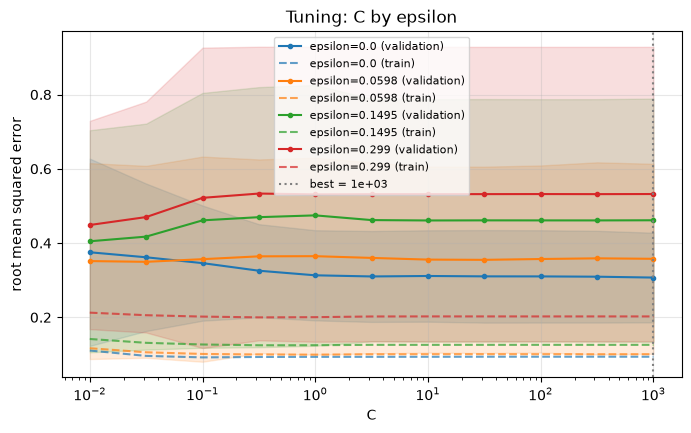

In [3]:
plot_tuning(lin_search, "svr__C", by="svr__epsilon")

<Axes: title={'center': 'CV root mean squared error'}, xlabel='C', ylabel='epsilon'>

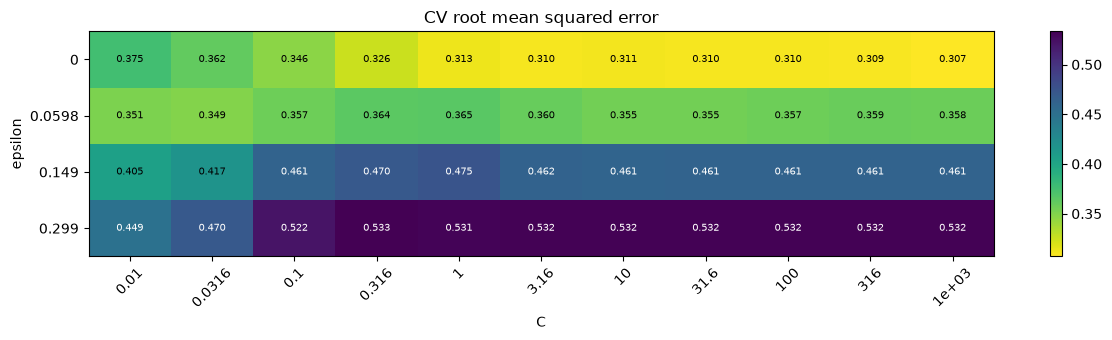

In [4]:
plot_tuning_heatmap(lin_search, "svr__C", "svr__epsilon")

<Axes: title={'center': 'Linear SVR: coefficients (per 1 sd)'}>

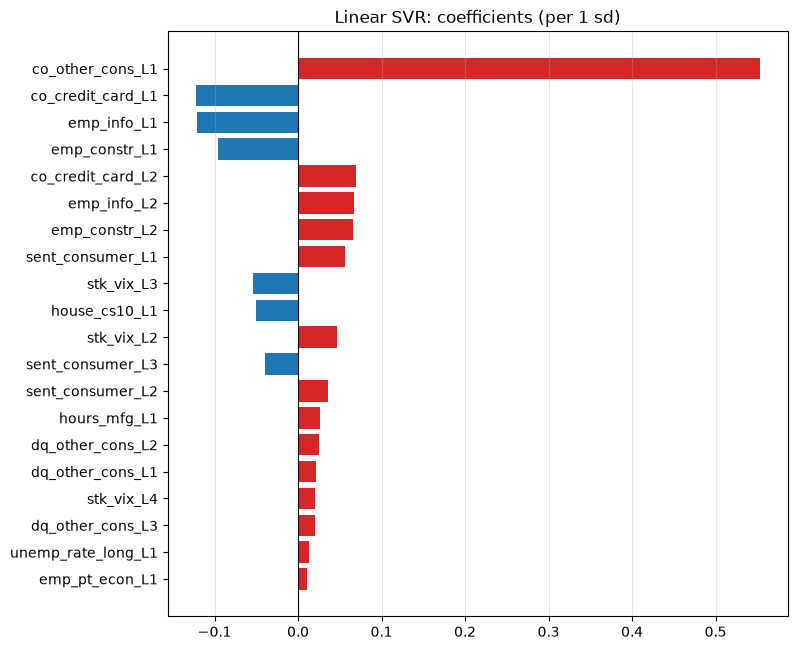

In [5]:
plot_feature_weights(lin_best, X_train, top=20, title="Linear SVR: coefficients (per 1 sd)")

In [6]:
score(lin_best, X_train, X_test, y_train, y_test)

,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.179,0.078,0.910,0.848,92.0
model - test,0.420,0.179,-1.727,0.432,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.117,0.095,0.694,0.444,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


In [7]:
record("SVR (linear)", lin_best, X_train, X_test, y_train, y_test, search=lin_search)

recorded 'SVR (linear)' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.179,0.078,0.910,0.848,92.0
model - test,0.420,0.179,-1.727,0.432,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.117,0.095,0.694,0.444,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 3. Kernel Trick: Linear vs Poly vs RBF
Each kernel has its own settings, so the grid is a list of three dictionaries.

In [8]:
kernel_grid = [
    {"svr__kernel": ["linear"], "svr__C": C_GRID, "svr__epsilon": EPS_GRID},
    {"svr__kernel": ["poly"],   "svr__C": C_GRID, "svr__epsilon": EPS_GRID, "svr__degree": [2, 3],
     "svr__coef0": [1.0]},
    {"svr__kernel": ["rbf"],    "svr__C": C_GRID, "svr__epsilon": EPS_GRID, "svr__gamma": GAMMA_GRID},
]
ker_search = tune(make_pipeline(*preprocess(scale=True), SVR()), kernel_grid, X_train, y_train)
ker_best = ker_search.best_estimator_

best params: {'svr__C': np.float64(1000.0), 'svr__epsilon': np.float64(0.0), 'svr__kernel': 'linear'}
best CV root_mean_squared_error: 0.3070


In [10]:
# best CV error each kernel can reach (each at its own best settings)
t = tuning_table(ker_search)
t.sort_values(["rank", "svr__C"]).groupby("svr__kernel").first()[
    ["svr__C", "svr__epsilon", "svr__gamma", "svr__degree", "cv_root_mean_squared_error", "train_root_mean_squared_error", "gap (cv - train)"]]

,svr__C,svr__epsilon,svr__gamma,svr__degree,cv_root_mean_squared_error,train_root_mean_squared_error,gap (cv - train)
svr__kernel,,,,,,,
linear,1000.000000,0.0000,NaN,NaN,0.307046,0.093793,0.213253
poly,0.100000,0.0000,NaN,3.0,0.327995,0.065506,0.262489
rbf,3.162278,0.0598,0.001,NaN,0.387167,0.120760,0.266406


<Axes: title={'center': 'Tuning: C by kernel'}, xlabel='C', ylabel='root mean squared error'>

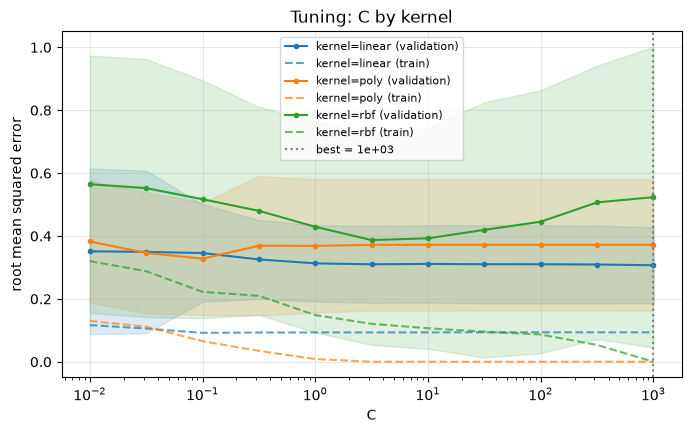

In [11]:
plot_tuning(ker_search, "svr__C", by="svr__kernel")

> **Comparing Lines:** if rbf/poly reach a lower **validation** error than linear, the relationships are non-linear enough for the kernel trick to help. If their **train** error (dashed) drops far below their validation error, the extra flexibility is fitting noise.

<Axes: title={'center': 'CV root mean squared error'}, xlabel='C', ylabel='gamma'>

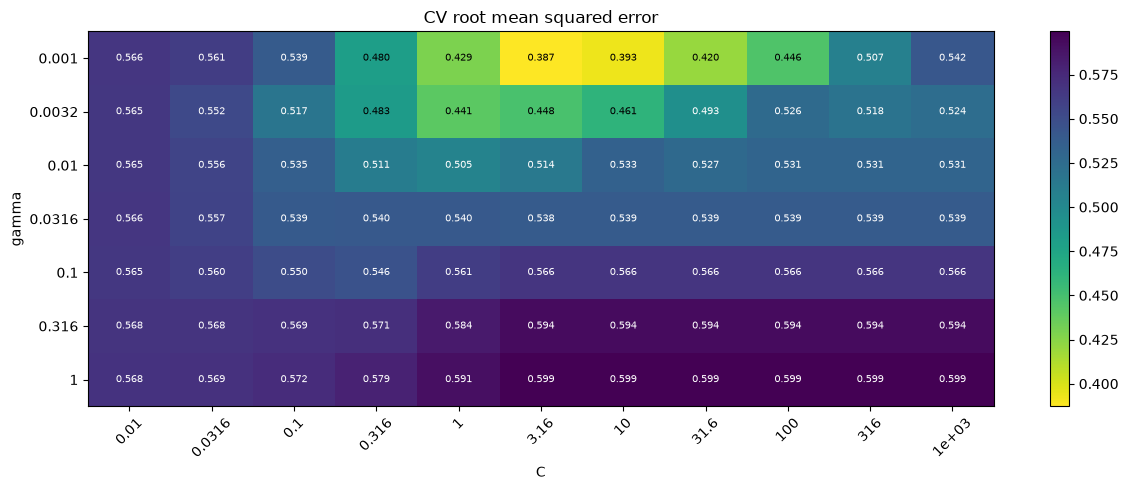

In [12]:
plot_tuning_heatmap(ker_search, "svr__C", "svr__gamma")      # rbf only: regularization x kernel width

> **Reading the C × gamma map:** top-right (large C, large gamma) = very flexible, usually overfit; bottom-left = very rigid, usually underfit. The best region is often a diagonal band: more flexibility from gamma needs more regularization from C.

#### 1. What the kernel trick does to the fitted relationship
Vary one feature across its training range, hold all others at their median, and plot each model's forecast. Linear gives a straight line; rbf/poly can bend.

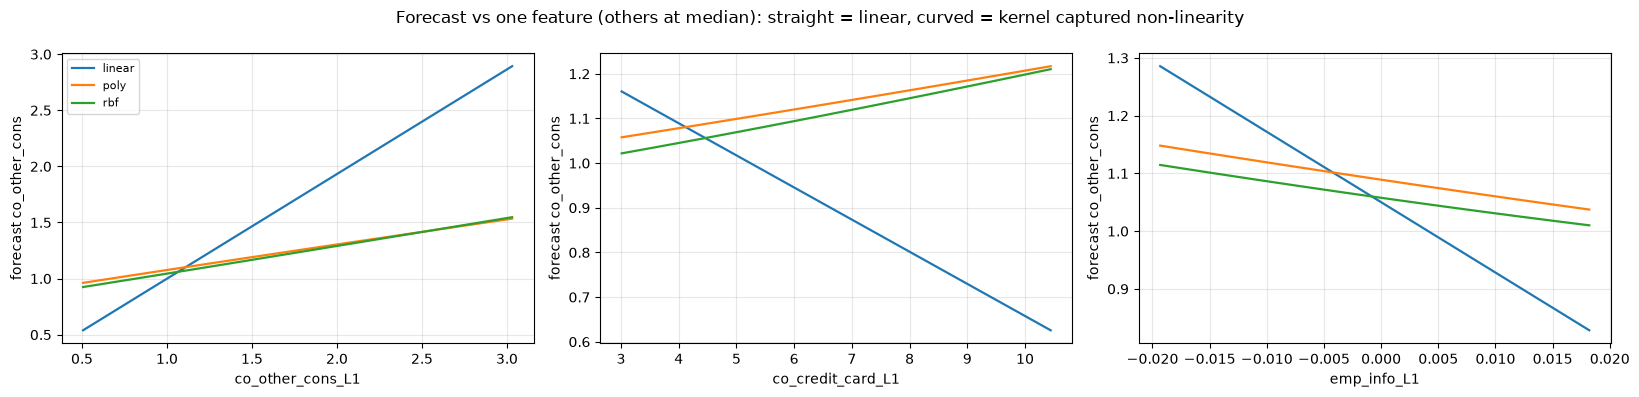

In [13]:
# best model of each kernel type, refit on the full training period
best_by_kernel = {}
for k in ["linear", "poly", "rbf"]:
    row = t[t["svr__kernel"] == k].sort_values(["rank", "svr__C"]).iloc[0]   # ties -> smaller C (simpler)
    params = {c: row[c] for c in ["svr__C", "svr__epsilon", "svr__gamma", "svr__degree", "svr__coef0"]
              if c in row and pd.notna(row[c])}
    if "svr__degree" in params:
        params["svr__degree"] = int(params["svr__degree"])
    best_by_kernel[k] = make_pipeline(*preprocess(scale=True), SVR(kernel=k)).set_params(**params).fit(X_train, y_train)

def response_curves(models, features, X, n=60):
    fig, axes = plt.subplots(1, len(features), figsize=(5.5 * len(features), 4), squeeze=False)
    base = X.median()
    for ax, f in zip(axes[0], features):
        grid = np.linspace(X[f].quantile(0.02), X[f].quantile(0.98), n)
        Xg = pd.DataFrame([base] * n).reset_index(drop=True)
        Xg[f] = grid
        for name, m in models.items():
            ax.plot(grid, m.predict(Xg), label=name, lw=1.6)
        ax.set_xlabel(f); ax.set_ylabel(f"forecast {meta['target']}"); ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle("Forecast vs one feature (others at median): straight = linear, curved = kernel captured non-linearity")
    plt.tight_layout(); plt.show()

# the most important features by permutation on the best kernel model
perm_ker = permutation_table(ker_best, X_train, y_train, X_test, y_test, n_repeats=15)
top_feats = list(perm_ker["train importance"].sort_values(ascending=False).index[:3])
response_curves(best_by_kernel, top_feats, X_train)

### 4. SVM Regularization: C and Epsilon
Holding the kernel fixed at the best one found above, sweep C and watch three things: training error, validation error, and **how many quarters become support vectors**.

kernel settings held fixed: {'svr__epsilon': np.float64(0.0), 'svr__kernel': 'linear'}


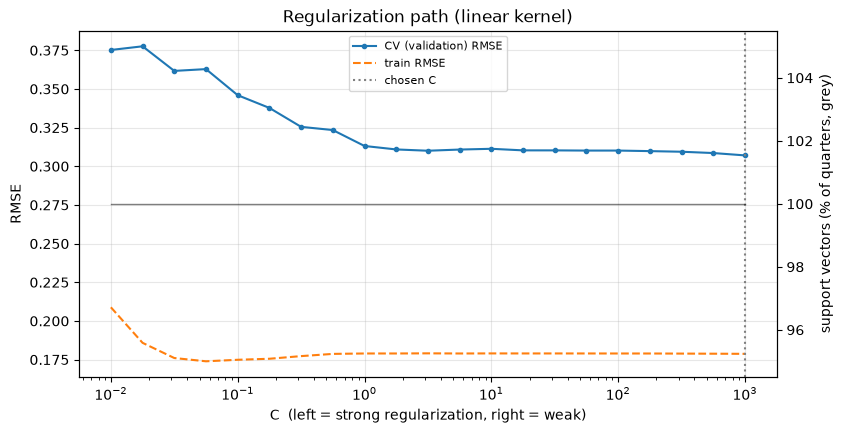

,C,train RMSE,CV RMSE,support vectors (% of quarters)
0,0.0100,0.2088,0.3752,100.0
1,0.0178,0.1858,0.3776,100.0
2,0.0316,0.1760,0.3617,100.0
3,0.0562,0.1739,0.3628,100.0
4,0.1000,0.1749,0.3460,100.0
5,0.1778,0.1756,0.3377,100.0
6,0.3162,0.1773,0.3255,100.0
7,0.5623,0.1787,0.3234,100.0
8,1.0000,0.1790,0.3131,100.0
9,1.7783,0.1790,0.3109,100.0


In [14]:
best_kernel = ker_search.best_params_["svr__kernel"]
fixed = {k: v for k, v in ker_search.best_params_.items() if k not in ("svr__C",)}
print("kernel settings held fixed:", fixed)

rows = []
for C in np.logspace(-2, 3, 21):
    m = make_pipeline(*preprocess(scale=True), SVR()).set_params(**fixed, svr__C=C)
    cv_rmse = -cross_val_score(m, X_train, y_train, cv=TimeSeriesSplit(5), scoring="neg_root_mean_squared_error").mean()
    m.fit(X_train, y_train)
    tr_rmse = float(np.sqrt(np.mean((m.predict(X_train) - y_train) ** 2)))
    rows.append({"C": C, "train RMSE": tr_rmse, "CV RMSE": cv_rmse,
                 "support vectors (% of quarters)": 100 * m[-1].support_.size / len(X_train)})
reg = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(reg["C"], reg["CV RMSE"], marker="o", ms=3, label="CV (validation) RMSE")
ax.plot(reg["C"], reg["train RMSE"], ls="--", label="train RMSE")
ax.axvline(ker_search.best_params_["svr__C"], color="grey", ls=":", label="chosen C")
ax.set_xscale("log"); ax.set_xlabel("C  (left = strong regularization, right = weak)"); ax.set_ylabel("RMSE")
ax2 = ax.twinx()
ax2.plot(reg["C"], reg["support vectors (% of quarters)"], color="black", alpha=0.5, lw=1)
ax2.set_ylabel("support vectors (% of quarters, grey)")
ax.legend(fontsize=8, loc="upper center"); ax.grid(alpha=0.3)
ax.set_title(f"Regularization path ({best_kernel} kernel)")
plt.show()
reg.round(4)

> **Reading it:** as C grows, training error keeps falling while validation error flattens or rises: the gap is overfitting. The chosen C sits where validation error is lowest.

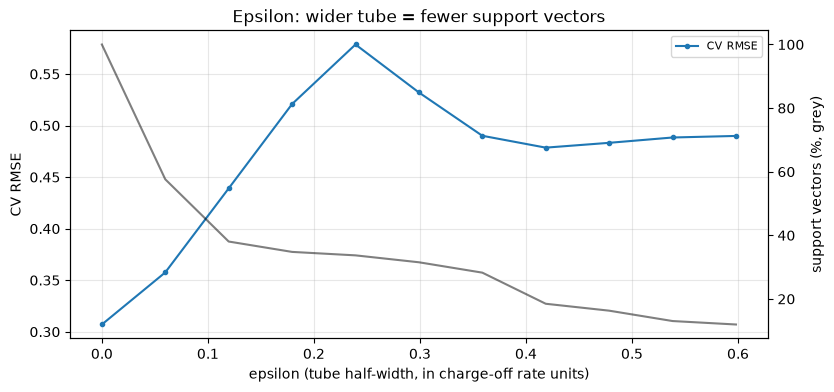

In [15]:
# epsilon: a wider tube ignores more small errors -> fewer support vectors -> simpler model
best_C = ker_search.best_params_["svr__C"]
eps_rows = []
for eps in np.linspace(0, 1.0, 11) * y_train.std():
    m = make_pipeline(*preprocess(scale=True), SVR()).set_params(**{**fixed, "svr__epsilon": eps}, svr__C=best_C)
    cv_rmse = -cross_val_score(m, X_train, y_train, cv=TimeSeriesSplit(5), scoring="neg_root_mean_squared_error").mean()
    m.fit(X_train, y_train)
    eps_rows.append({"epsilon": eps, "CV RMSE": cv_rmse,
                     "support vectors (% of quarters)": 100 * m[-1].support_.size / len(X_train)})
eps_df = pd.DataFrame(eps_rows)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(eps_df["epsilon"], eps_df["CV RMSE"], marker="o", ms=3, label="CV RMSE")
ax.set_xlabel("epsilon (tube half-width, in charge-off rate units)"); ax.set_ylabel("CV RMSE")
ax2 = ax.twinx(); ax2.plot(eps_df["epsilon"], eps_df["support vectors (% of quarters)"], color="black", alpha=0.5)
ax2.set_ylabel("support vectors (%, grey)")
ax.set_title("Epsilon: wider tube = fewer support vectors"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

### 5. Best Kernel SVR: Overfitting and Accuracy

In [16]:
print("best settings:", ker_search.best_params_)
score(ker_best, X_train, X_test, y_train, y_test)

best settings: {'svr__C': np.float64(1000.0), 'svr__epsilon': np.float64(0.0), 'svr__kernel': 'linear'}


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.179,0.078,0.910,0.848,92.0
model - test,0.420,0.179,-1.727,0.432,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.117,0.095,0.694,0.444,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


<Axes: title={'center': 'Best SVR: actual vs forecast'}, ylabel='co_other_cons'>

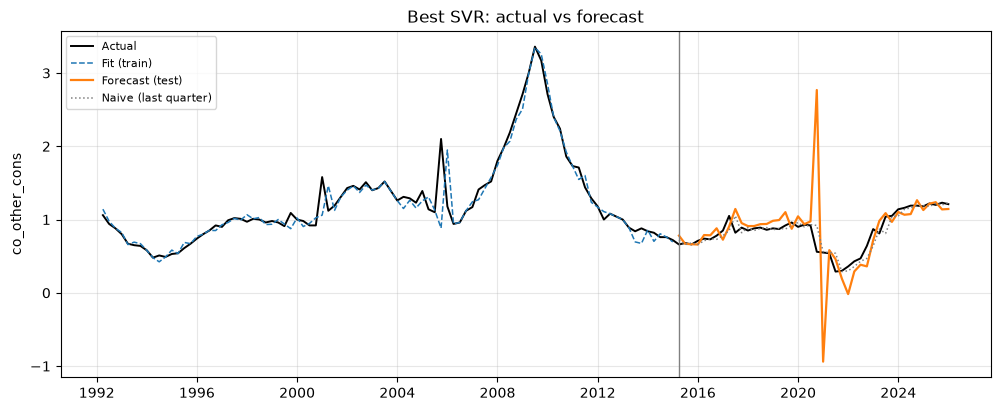

In [17]:
plot_forecast(ker_best, X_train, X_test, y_train, y_test, title="Best SVR: actual vs forecast")

<Axes: title={'center': 'Permutation importance (big train, small test = likely overfit)'}, xlabel='drop in root_mean_squared_error when shuffled'>

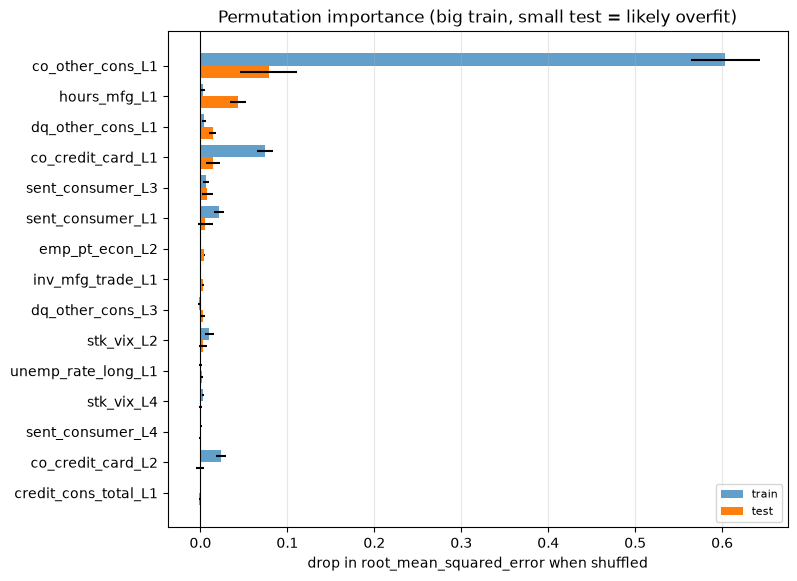

In [18]:
plot_permutation(perm_ker, top=15)

> **Note:** rbf/poly kernels have no per-feature coefficients, so permutation importance is how to see what the model relies on (and whether it relies on features differently in train vs test).

In [19]:
record("SVR (kernel)", ker_best, X_train, X_test, y_train, y_test, search=ker_search,
       notes=str(ker_search.best_params_))

recorded 'SVR (kernel)' -> /workspaces/DX799-O1/model_data/results


,RMSE,MAE,R2,DirAcc,n
model - train (in-sample),0.179,0.078,0.910,0.848,92.0
model - test,0.420,0.179,-1.727,0.432,44.0
naive - test,0.104,0.066,0.832,NaN,44.0
model - test excl. 2020-21,0.117,0.095,0.694,0.444,36.0
naive - test excl. 2020-21,0.089,0.060,0.824,NaN,36.0


### 6. SV Classifier On Y/N Target
Same question as nbk4 (above the training median?). Tuned on **accuracy** with 12-quarter validation blocks, because some blocks contain only one class (ROC AUC would be undefined).

In [20]:
y_train_bin, y_test_bin, thr = make_binary_target(y_train, y_test)
CV_CLS = TimeSeriesSplit(n_splits=4, test_size=12)
svc_grid = [
    {"svc__kernel": ["linear"], "svc__C": C_GRID},
    {"svc__kernel": ["rbf"], "svc__C": C_GRID, "svc__gamma": GAMMA_GRID},
    {"svc__kernel": ["poly"], "svc__C": C_GRID, "svc__degree": [2, 3], "svc__coef0": [1.0]},
]
svc_search = tune(make_pipeline(*preprocess(scale=True), SVC()), svc_grid, X_train, y_train_bin,
                  cv=CV_CLS, scoring="accuracy")
svc_best = svc_search.best_estimator_

threshold = 1.050 (training 50% quantile); share above: train 50%, test 20%
best params: {'svc__C': np.float64(1.0), 'svc__gamma': np.float64(0.1), 'svc__kernel': 'rbf'}
best CV accuracy: 0.6250


<Axes: title={'center': 'Tuning: C by kernel'}, xlabel='C', ylabel='accuracy'>

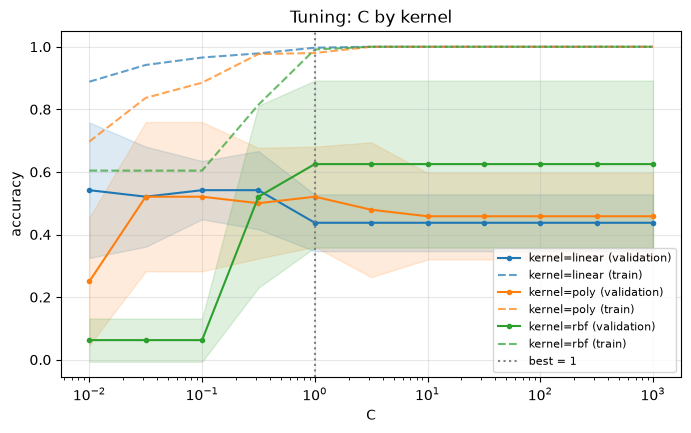

In [21]:
plot_tuning(svc_search, "svc__C", by="svc__kernel")

In [22]:
score_classifier(svc_best, X_train, X_test, y_train_bin, y_test_bin)

,Accuracy,Precision,Recall,F1,n
train (in-sample),0.989,1.000,0.978,0.989,92.0
test,0.432,0.265,1.000,0.419,44.0
always-majority - test,0.795,NaN,NaN,NaN,44.0


In [23]:
record("SVC", svc_best, X_train, X_test, y_train_bin, y_test_bin, search=svc_search,
       notes=f"high = above training median {thr:.3f}; {svc_search.best_params_}")

recorded 'SVC' -> /workspaces/DX799-O1/model_data/results


,Accuracy,Precision,Recall,F1,n
train (in-sample),0.989,1.000,0.978,0.989,92.0
test,0.432,0.265,1.000,0.419,44.0
always-majority - test,0.795,NaN,NaN,NaN,44.0


### 7. Compare

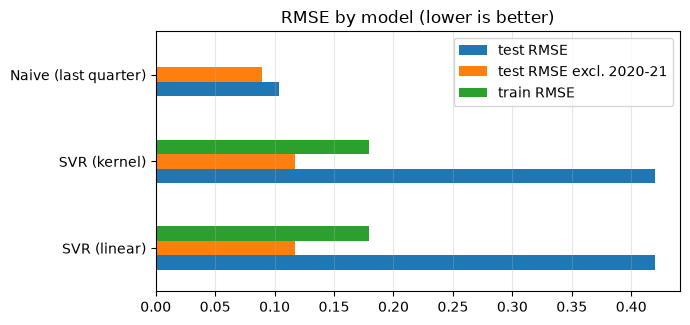

,type,test RMSE,test MAE,test R2,test DirAcc,test RMSE excl. 2020-21,train RMSE,overfit gap (test - train RMSE),CV score,CV metric,best params,saved
Naive (last quarter),baseline,0.104,0.066,0.832,NaN,0.089,NaN,NaN,NaN,NaN,NaN,NaN
SVR (kernel),regressor,0.42,0.179,-1.727,0.432,0.117,0.179,0.241,0.307046,root_mean_squared_error,"{'svr__C': 1000.0, 'svr__epsilon': 0.0, 'svr__...",2026-10-18 04:39
SVR (linear),regressor,0.42,0.179,-1.727,0.432,0.117,0.179,0.241,0.307046,root_mean_squared_error,"{'svr__C': 1000.0, 'svr__epsilon': 0.0}",2026-10-18 04:28


In [24]:
nb5 = ["SVR (linear)", "SVR (kernel)"]
compare(results={k: v for k, v in load_results().items() if k in nb5})

<Axes: title={'center': 'Test-period forecasts by model'}, ylabel='co_other_cons'>

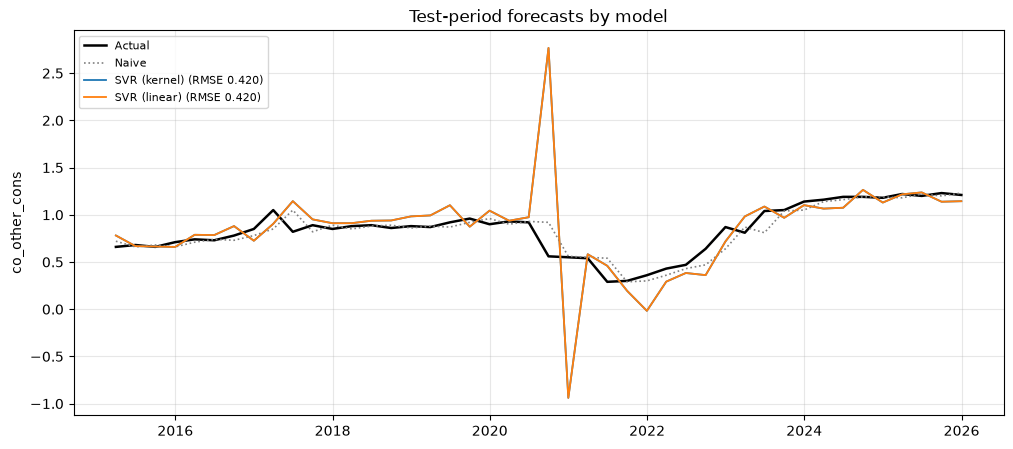

In [25]:
plot_forecasts(names=nb5)

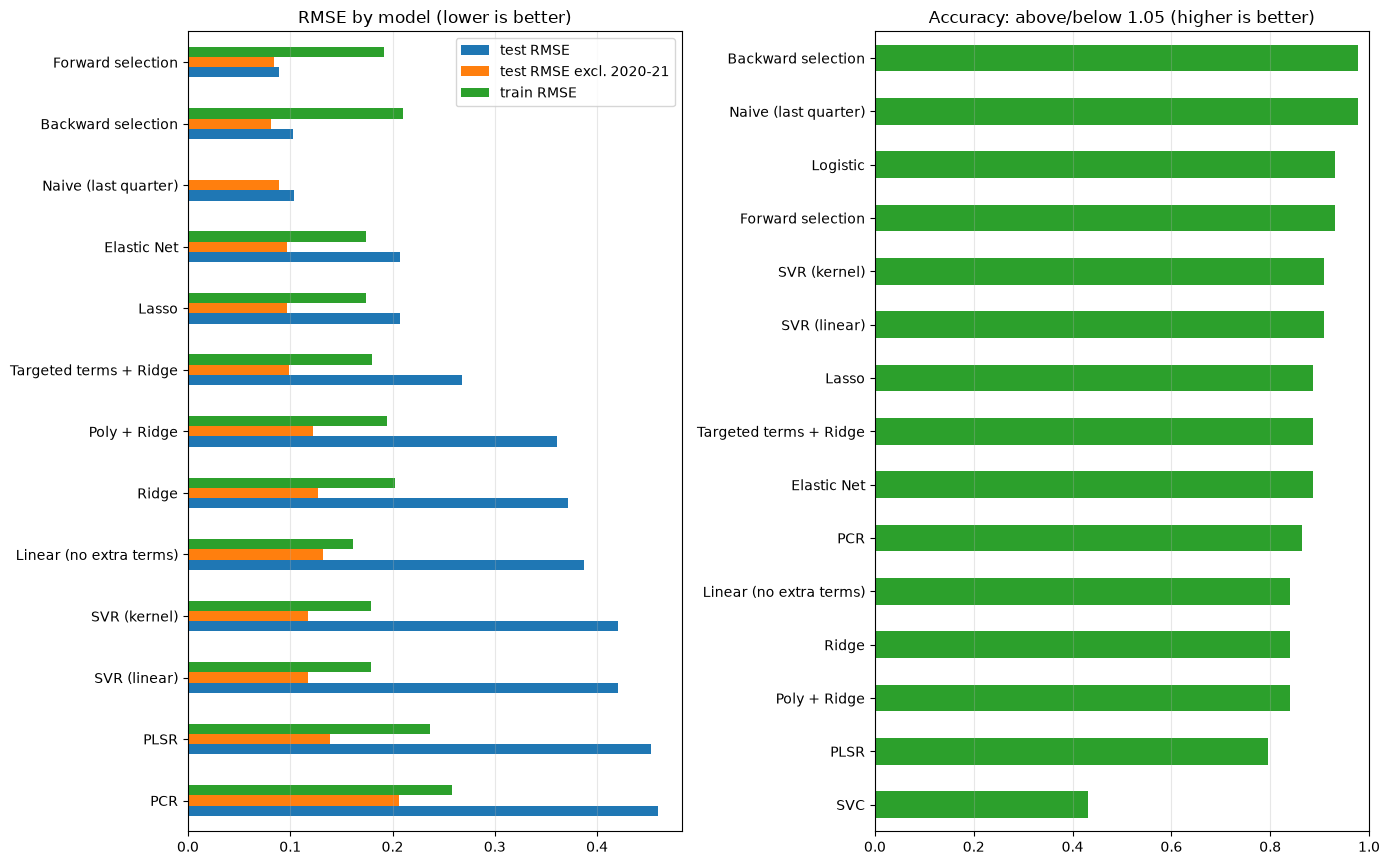

,type,test RMSE,test MAE,test R2,test DirAcc,test RMSE excl. 2020-21,train RMSE,overfit gap (test - train RMSE),Accuracy (vs threshold),CV score,CV metric,best params,saved,test ROC_AUC
Forward selection,regressor,0.089,0.065,0.878,0.659,0.084,0.192,-0.103,0.931818,0.22666,root_mean_squared_error,{'sequentialfeatureselector__n_features_to_sel...,2026-10-18 03:17,NaN
Backward selection,regressor,0.103,0.063,0.836,0.636,0.081,0.21,-0.107,0.977273,0.235818,root_mean_squared_error,{'sequentialfeatureselector__n_features_to_sel...,2026-10-18 03:17,NaN
Naive (last quarter),baseline,0.104,0.066,0.832,NaN,0.089,NaN,NaN,0.977273,NaN,NaN,NaN,NaN,NaN
Elastic Net,regressor,0.207,0.114,0.34,0.636,0.097,0.174,0.033,0.886364,0.336756,root_mean_squared_error,"{'elasticnet__alpha': 0.019573417814876617, 'e...",2026-10-18 02:11,NaN
Lasso,regressor,0.207,0.114,0.339,0.636,0.097,0.174,0.033,0.886364,0.336352,root_mean_squared_error,{'lasso__alpha': 0.020309176209047347},2026-10-18 02:06,NaN
Targeted terms + Ridge,regressor,0.268,0.139,-0.109,0.614,0.099,0.18,0.088,0.886364,0.353107,root_mean_squared_error,"{'addterms__pairs': (('dq_other_cons_L1', 'une...",2026-10-18 01:43,NaN
Poly + Ridge,regressor,0.361,0.157,-1.014,0.636,0.122,0.195,0.166,0.840909,0.38412,root_mean_squared_error,"{'polynomialfeatures__degree': 1, 'polynomialf...",2026-10-18 01:10,NaN
Ridge,regressor,0.372,0.169,-1.138,0.614,0.127,0.202,0.17,0.840909,0.384148,root_mean_squared_error,{'ridge__alpha': 32.57020655659783},2026-10-18 02:00,NaN
Linear (no extra terms),regressor,0.387,0.179,-1.307,0.591,0.132,0.161,0.226,0.840909,None,None,None,2026-10-18 01:10,NaN
SVR (kernel),regressor,0.42,0.179,-1.727,0.432,0.117,0.179,0.241,0.909091,0.307046,root_mean_squared_error,"{'svr__C': 1000.0, 'svr__epsilon': 0.0, 'svr__...",2026-10-18 04:39,NaN


In [26]:
compare(threshold=thr)        # every model so far, incl. SVC and Logistic, on the same yes/no accuracy

In [27]:
export_predictions(ker_best, X_train, X_test, y_train, y_test, name="SVR (kernel)")
export_predictions(lin_best, X_train, X_test, y_train, y_test, name="SVR (linear)")
reg.to_csv(f"{EXPORT_DIR}/nb5_regularization_path.csv", index=False)
tuning_table(ker_search).to_csv(f"{EXPORT_DIR}/nb5_kernel_tuning.csv", index=False)

saved 136 rows -> /workspaces/DX799-O1/model_data/exports/SVR__kernel_predictions.csv
saved 136 rows -> /workspaces/DX799-O1/model_data/exports/SVR__linear_predictions.csv


### 8. Notes

**Goal:** forecast `co_other_cons` with support vector regression (SVR), show how the **kernel trick** lets a linear method capture non-linear relationships, and how **regularization** (C, epsilon) controls overfitting. A support vector classifier (SVC) is also fit on the same yes/no target as notebook 4.

**SVR in one paragraph:** SVR fits a function and ignores errors smaller than **epsilon** (a "tube" around the prediction). Only quarters outside the tube, the **support vectors**, shape the model. **C** sets how much those errors cost:
- small C → errors are cheap → flatter, simpler function (strong regularization, may underfit)
- large C → errors are expensive → the function bends to fit more quarters (weak regularization, may overfit)

**Kernel trick:** SVR only needs the *similarity* between pairs of quarters. A kernel computes that similarity as if the features had been mapped into a much richer space, without ever building those features:
- `linear`: plain dot product (same shape of model as Ridge)
- `poly` (degree d): similarity includes all products of features up to degree d (like notebook 1's polynomial terms, done implicitly)
- `rbf`: similarity decays with distance; **gamma** sets how fast (large gamma → only very similar quarters matter → wiggly, overfit-prone)

**Scaling is required:** kernels measure distances between quarters, so unscaled features with large units would dominate.

**Lags:** same lagged features; with rbf/poly kernels the model can capture interactions between lags (e.g. delinquency mattering more when unemployment is high) without listing them by hand.

- **Kernel trick:** best CV error per kernel; whether rbf/poly beat linear; the response curves show where the relationship bends (or doesn't).
- **Regularization:** chosen C and epsilon; regularization path (train vs CV RMSE and support vectors vs C); C × gamma heatmap (flexibility vs regularization trade-off).
- **Lags:** permutation importance shows which lagged features the kernel model relies on; kernels can use interactions between lags without listing them.
- **Overfitting:** train–CV gap along C; permutation train vs test; train–test gap in `compare()`.
- **Classification:** SVC vs logistic on the same yes/no threshold (`compare(threshold=thr)`).